**Выполнил:** Тальян Антон

In [ ]:
!pip install factor_analyzer

# Факторный анализ химических показателей вина

Химические показатели вина измеряются десятками величин, но описывать
вино по всему набору неудобно: часть показателей дублирует друг друга и
отражает одни и те же скрытые свойства, такие как кислотность,
минеральный состав и плотность. Факторный анализ находит такие скрытые
(латентные) факторы и сжимает набор измерений до нескольких
содержательных измерений.

В работе отрабатывается полный цикл факторного анализа: проверка
пригодности данных, отбор переменных, выбор числа факторов, извлечение,
вращение нагрузок и интерпретация. Все расчёты выполняются готовыми
функциями пакета `factor_analyzer`: собственные вспомогательные функции
не требуются.

## Теория

### Основная идея факторного анализа

**Факторный анализ** объясняет корреляции между наблюдаемыми переменными
действием небольшого числа латентных (не наблюдаемых напрямую) факторов.

- Переменные коррелируют не попарно, а потому что за ними стоит общая
  причина: фактор.
- Задача: подобрать нагрузки так, чтобы матрица
  $\Lambda\Lambda^\top + \Psi$ воспроизводила корреляции между
  **разными** переменными.
- Фактор является расчётной конструкцией, получаемой из корреляционной
  матрицы, а не измеряемой величиной.
- Число факторов $k$ задаёт исследователь, поэтому решение задачи не
  единственно.

### Модель факторного анализа

Каждая наблюдаемая переменная представляется линейной комбинацией общих
факторов и собственной составляющей:

$$
x_i = \lambda_{i1}f_1 + \lambda_{i2}f_2 + \dots + \lambda_{ik}f_k + u_i, \quad i = 1, \dots, p
$$

- $f_j$ — общие (латентные) факторы, $u_i$ — характерность переменной
  $x_i$;
- нагрузки $\lambda_{ij}$ показывают вклад фактора $f_j$ в переменную
  $x_i$;
- модель линейна, число факторов $k$ задано заранее и меньше числа
  переменных;
- допущения: факторы не коррелируют между собой и с характерностями,
  характерности разных переменных не коррелируют.

### Общность и характерность

Дисперсия стандартизованной переменной распадается на две части:

$$
1 = \sum_{j=1}^{k}\lambda_{ij}^2 + \psi_i = h_i^2 + \psi_i
$$

- $h_i^2 = \sum_{j=1}^{k}\lambda_{ij}^2$ — **общность**
  (коммунальность): доля дисперсии переменной, которую она делит с
  другими переменными через общие факторы;
- $\psi_i$ — **характерность**: уникальная часть дисперсии, включая
  специфику переменной и ошибку измерения;
- общность служит показателем качества модели для отдельной переменной:
  при $h_i^2 < 0{,}3$ переменная факторами почти не объясняется.

### Факторные нагрузки

- Если факторы не коррелируют между собой, нагрузка $\lambda_{ij}$
  является коэффициентом корреляции между переменной $x_i$ и фактором
  $f_j$; нагрузки читаются так же, как в методе главных компонент.
- Значения нагрузок лежат в $[-1; 1]$; практически значимыми считаются
  нагрузки по модулю больше 0,4.
- Переменная с двумя и более значимыми нагрузками называется
  **кросс-нагрузкой**: она связана сразу с несколькими факторами.
- Нагрузки читают по столбцам: фактор описывают переменные с наибольшими
  нагрузками в его столбце.

### Требования к данным и проверка пригодности

Факторный анализ строится на коэффициентах корреляции, поэтому к данным
предъявляются требования: независимые наблюдения, интервальные шкалы
(порядковые не менее пяти градаций), отсутствие сильных выбросов, объём
выборки не менее 5–10 наблюдений на переменную. Пригодность проверяют
двумя показателями.

**Тест сферичности Бартлетта.** Проверяется $H_0$: корреляционная
матрица генеральной совокупности единичная, то есть переменные
независимы. Статистика опирается на определитель корреляционной матрицы
$R$ и объём выборки $n$:

$$
\chi^2 = -\left(n - 1 - \frac{2p + 5}{6}\right)\ln|R|, \qquad \mathrm{df} = \frac{p(p-1)}{2}
$$

Правило чтения: $p < 0{,}05$ означает, что основания отвергнуть $H_0$
есть, корреляции значимы и факторный анализ применим; $p > 0{,}05$
означает, что оснований отвергнуть $H_0$ нет, связи слабые и факторная
модель не оправдана. При больших $n$ тест почти всегда значим, поэтому
одного его недостаточно.

**KMO** (мера адекватности Кайзера—Майера—Олкина) сравнивает обычные
корреляции переменных с частными: если после исключения остальных
переменных связи исчезают, общие факторы объясняют многое. Значение
лежит в диапазоне от 0 до 1. Градации: больше 0,9 — отлично; 0,8–0,9 —
хорошо; 0,7–0,8 — посредственно; 0,6–0,7 — удовлетворительно; 0,5–0,6 —
плохо; меньше 0,5 — неприемлемо. KMO считают и для каждой переменной
отдельно: низкое значение указывает на переменную, которая плохо
укладывается в общую структуру, и её исключают из анализа.

### Собственные значения и выбор числа факторов

**Собственное значение** $e_i$ корреляционной матрицы показывает,
сколько дисперсии приходится на соответствующее направление; единица
измерения — дисперсия одной стандартизованной переменной. Сумма
собственных значений равна числу переменных: $\sum_{i=1}^{p} e_i = p$, а
доля дисперсии фактора номер $i$ равна $e_i / p$. Собственные значения
считают по исходной корреляционной матрице до всякой факторной модели, и
они служат ориентиром при выборе числа факторов:

- **критерий Кайзера**: оставляют факторы с $e_i > 1$, то есть
  объясняющие больше дисперсии, чем одна исходная переменная;
- **график каменистой осыпи**: собственные значения по убыванию; число
  факторов выбирают до перелома, после которого спад становится пологим;
- **накопленная доля дисперсии**: часто требуют, чтобы выбранные факторы
  объясняли не менее 60–70 % дисперсии.

Ориентиры могут расходиться, тогда решение принимают по совокупности
аргументов и содержательной интерпретируемости факторов.

### Извлечение факторов

Методы извлечения подбирают нагрузки разными способами, но преследуют
одну цель: воспроизвести корреляции между переменными.

- **Метод главных осей** (principal axis, `method='principal'`):
  диагональ корреляционной матрицы заменяют на оценки общностей и
  итеративно уточняют их до сходимости.
- **Метод минимальных остатков** (MINRES, `method='minres'`): нагрузки
  подбираются минимизацией суммы квадратов остаточных корреляций.
- **Максимальное правдоподобие** (`method='ml'`): итеративная оценка
  нагрузок и дисперсий случайных компонент при предположении о
  многомерной нормальности; общность переменной равна $1 - \psi_i$, где
  $\psi_i$ — оценка характерности.

Качество воспроизведения проверяют **остаточными корреляциями**:
$E = R - \Lambda\Lambda^\top$ с нулевой диагональю. Малые остатки
означают, что модель хорошо описывает наблюдаемые корреляции. В версии
пакета 0.5.1 готового метода для остаточной матрицы нет, остатки
вычисляются как разность матриц.

### Вращение факторных нагрузок

Найденное решение не единственно: любое ортогональное преобразование
нагрузок даёт ту же воспроизведённую корреляционную матрицу. Вращение
перераспределяет нагрузки между факторами, чтобы получить **простую
структуру**: каждая переменная связана с одним фактором, остальные
нагрузки близки к нулю. Цель вращения — читаемость, а не улучшение
качества модели.

| Вращение | Тип | Идея |
|------------------------|------------------------|------------------------|
| **Варимакс** (varimax) | ортогональное | минимизирует число переменных с высокой нагрузкой на каждый фактор |
| **Квартимакс** (quartimax) | ортогональное | минимизирует число факторов, нужных для объяснения каждой переменной |
| **Промакс** (promax) | косоугольное | допускает корреляции факторов, строится на основе варимакс-решения |
| **Облимин** (oblimin) | косоугольное | наиболее гибкое косоугольное вращение |

Свойства вращения, которые важно проверять на практике:

- вращение **не меняет** общности переменных и суммарную объяснённую
  дисперсию: дисперсия лишь перераспределяется между факторами, поэтому
  рост объяснённой дисперсии после вращения служит признаком ошибки в
  расчётах;
- знак столбца нагрузок произволен: умножение всех нагрузок фактора на
  $-1$ даёт то же решение;
- порядок факторов также произволен: нумерацию задаёт программа;
- ортогональное вращение сохраняет некоррелированность факторов,
  косоугольное допускает их корреляции и выводит две таблицы: паттерн
  (вклады) и структуру (корреляции); интерпретируют обычно паттерн. Тип
  вращения обязательно указывают в отчёте.

### Порядок проведения факторного анализа

1.  Загрузить данные; пакет стандартизует переменные сам, поскольку
    работает с корреляционной матрицей.
2.  Проверить пригодность: тест Бартлетта и KMO; при необходимости
    исключить переменные с низким индивидуальным KMO и повторить
    проверку.
3.  Выбрать метод извлечения факторов.
4.  Задать число факторов и извлечь их.
5.  Вращать матрицу нагрузок.
6.  Интерпретировать факторы; при неудаче вернуться к шагам 3–5.

### Типичные ошибки

- Начинать анализ, не проверив корреляции: на слабых связях факторы
  неустойчивы.
- Читать тест Бартлетта наоборот: при $p > 0{,}05$ факторная модель не
  оправдана.
- Полагать, что одного теста Бартлетта достаточно, и пропускать KMO.
- Считать KMO один раз и не пересчитывать его после исключения
  переменной.
- Механически оставлять все факторы с $e > 1$, не сверяя решение с
  графиком осыпи и смыслом.
- Называть фактор по одной самой «громкой» переменной, не посмотрев
  остальные нагрузки столбца.
- Игнорировать кросс-нагрузки и путать долю объяснённой дисперсии со
  средней общностью: это разные величины.
- Трактовать факторы как причины: «фактор вызывает» вместо «фактор
  объясняет связи».
- Не указывать метод извлечения, число факторов и тип вращения:
  результат становится невоспроизводимым.

## Предварительные знания

Уверенная работа с `pandas`: загрузка данных, описательная статистика,
корреляционная матрица. Представление о стандартизации переменных и
коэффициенте корреляции. Базовое владение `matplotlib` для построения
линейных графиков.

## Окружение и зависимости

| Пакет | Версия окружения проекта | Назначение |
|------------------------|------------------------|------------------------|
| Python | 3.12 | интерпретатор |
| pandas | 3.1 | таблицы данных |
| numpy | 2.5 | массивы, матричные операции |
| matplotlib | 3.11 | графики |
| factor_analyzer | 0.5.1 | тесты пригодности, извлечение факторов, вращения |

В окружении проекта установлен `factor_analyzer` 0.5.1. Последняя версия
пакета устанавливается из репозитория разработчика:

``` text
%pip install --upgrade "factor-analyzer @ git+https://github.com/EducationalTestingService/factor_analyzer.git@main"
```

Команду выполняют в отдельной ячейке ноутбука, если нужна актуальная
версия пакета; для расчётов семинара достаточно установленной версии.
Для версии 0.5.1 характерно отсутствие метода остаточной матрицы
`get_residuals()`, поэтому остатки вычисляются вручную как разность
матриц.

Интернет требуется только для установки или обновления пакета; данные
находятся в файле проекта.

## Данные

Файл `data/winequality-red.csv`: 1599 образцов красного вина
португальского сорта Vinho Verde (набор Wine Quality из репозитория UCI
Machine Learning, Cortez et al., 2009), разделитель — запятая, пропусков
нет. Двенадцать столбцов:

- 11 числовых химических показателей: `fixed acidity` (титруемая
  кислотность), `volatile acidity` (летучая кислотность), `citric acid`
  (лимонная кислота), `residual sugar` (остаточный сахар), `chlorides`
  (хлориды), `free sulfur dioxide` (свободный диоксид серы),
  `total sulfur dioxide` (общий диоксид серы), `density` (плотность),
  `pH`, `sulphates` (сульфаты), `alcohol` (содержание алкоголя);
- `quality` — дегустационная оценка качества по шкале от 3 до 8; в
  анализе факторов она не участвует и служит внешним ориентиром.

## Как запускать

Ячейки выполняются сверху вниз без изменений. Каждое задание начинается
с ячейки с подготовительным кодом: она опирается на объекты, созданные в
предыдущих ячейках, и выполняется без ошибок как есть. Решение задания
записывается в ячейки `# TODO: напишите код здесь` под формулировкой.
Числа в формулировках не приводятся: значения, которые вы получите,
станут результатом работы и проверяются по критериям самопроверки.

## Пример: полный конвейер на четырёх показателях кислотности

Разберём все шаги факторного анализа на малом наборе: четырёх
показателях кислотности вина. Полный набор из 11 показателей
анализируется в заданиях.

Загрузка и обзор данных.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
from factor_analyzer import FactorAnalyzer, calculate_bartlett_sphericity, calculate_kmo

# узкий фильтр: предупреждение о псевдообращении возникает на почти вырожденных матрицах
warnings.filterwarnings(
    "ignore",
    message="The inverse of the variance-covariance matrix was calculated",
)

wine = pd.read_csv("data/winequality-red.csv")
print("строк и столбцов:", wine.shape)
print("пропусков:", int(wine.isna().sum().sum()))
print(wine["quality"].describe())

строк и столбцов: (1599, 12)
пропусков: 0
count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64


Проверка пригодности начинается с KMO: функция возвращает значение для
каждой переменной и общий показатель. Стандартизация не требуется, обе
проверки считаются по корреляционной матрице.

In [2]:
demo_cols = ["fixed acidity", "volatile acidity", "citric acid", "pH"]
X_demo = wine[demo_cols].astype(float)

# KMO по переменным и общий
kmo_per_variable, kmo_total = calculate_kmo(X_demo)
print("KMO общий: %.4f" % kmo_total)
print(pd.Series(kmo_per_variable, index=demo_cols).round(4).to_string())

KMO общий: 0.6652
fixed acidity       0.6496
volatile acidity    0.5840
citric acid         0.6598
pH                  0.7493


Тест сферичности Бартлетта: функция возвращает статистику и p-значение,
степени свободы вычисляются по числу переменных.

In [3]:
chi2_value, p_value = calculate_bartlett_sphericity(X_demo)
print("chi2 = %.2f, df = %d, p = %.3g"
      % (chi2_value, len(demo_cols) * (len(demo_cols) - 1) // 2, p_value))

chi2 = 2635.71, df = 6, p = 0


Собственные значения корреляционной матрицы возвращает обученная модель
с числом факторов, равным числу переменных: это разложение
корреляционной матрицы, а не факторная модель.

In [4]:
p_demo = len(demo_cols)
fa_eigen = FactorAnalyzer(n_factors=p_demo, rotation=None)
fa_eigen.fit(X_demo)
eigenvalues_demo = fa_eigen.get_eigenvalues()[0]

share_demo = eigenvalues_demo / p_demo * 100
print(pd.DataFrame({
    "Фактор": np.arange(1, p_demo + 1),
    "Собственное значение": eigenvalues_demo.round(3),
    "Доля дисперсии, %": share_demo.round(1),
    "Накопленная доля, %": np.cumsum(share_demo).round(1),
}).to_string(index=False))

 Фактор  Собственное значение  Доля дисперсии, %  Накопленная доля, %
      1                 2.509               62.7                 62.7
      2                 0.889               22.2                 84.9
      3                 0.370                9.3                 94.2
      4                 0.232                5.8                100.0


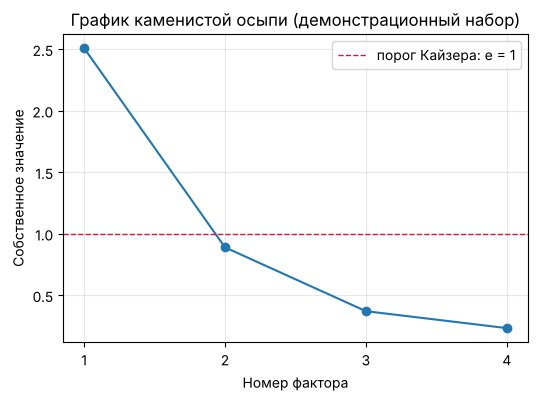

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, p_demo + 1), eigenvalues_demo, "o-")
ax.axhline(1, color="crimson", linestyle="--", linewidth=1, label="порог Кайзера: e = 1")
ax.set_xlabel("Номер фактора")
ax.set_ylabel("Собственное значение")
ax.set_title("График каменистой осыпи (демонстрационный набор)")
ax.set_xticks(np.arange(1, p_demo + 1))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Извлечение двух факторов методом максимального правдоподобия без
вращения: нагрузки находятся в `loadings_`, общности возвращает
`get_communalities()`, разложение дисперсии по факторам —
`get_factor_variance()`.

In [6]:
k_demo = 2
fa_demo = FactorAnalyzer(n_factors=k_demo, method="ml", rotation=None)
fa_demo.fit(X_demo)

L_demo = fa_demo.loadings_
print(pd.DataFrame(L_demo.round(3), index=demo_cols, columns=["Ф1", "Ф2"]).to_string())
print("общности:", np.round(fa_demo.get_communalities(), 3))
print("SS loadings:", np.round(fa_demo.get_factor_variance()[0], 3))

                     Ф1     Ф2
fixed acidity     0.934  0.208
volatile acidity -0.397  0.551
citric acid       0.812 -0.418
pH               -0.712 -0.086
общности: [0.916 0.461 0.834 0.514]
SS loadings: [2.197 0.529]


Остаточные корреляции считаются как разность корреляционной матрицы и
матрицы $\Lambda\Lambda^\top$; диагональ обнуляется, поскольку она
содержит общности, а не остатки.

In [7]:
R_demo = X_demo.corr().to_numpy()
residuals_demo = R_demo - L_demo @ L_demo.T
np.fill_diagonal(residuals_demo, 0.0)
print("максимальный |остаток|: %.4f" % np.abs(residuals_demo).max())

максимальный |остаток|: 0.0000


Вращение варимакс задаётся параметром `rotation`: пакет сам применяет
ортогональное вращение к найденным нагрузкам, отдельной функции не
требуется.

In [8]:
fa_demo_var = FactorAnalyzer(n_factors=k_demo, method="ml", rotation="varimax")
fa_demo_var.fit(X_demo)
L_demo_var = fa_demo_var.loadings_

print(pd.DataFrame(L_demo_var.round(3), index=demo_cols, columns=["Ф1", "Ф2"]).to_string())
print("SS до вращения:", np.round(fa_demo.get_factor_variance()[0], 3))
print("SS после вращения:", np.round(fa_demo_var.get_factor_variance()[0], 3))
print("суммы SS:", round(fa_demo.get_factor_variance()[0].sum(), 3),
      round(fa_demo_var.get_factor_variance()[0].sum(), 3))
print("общности после вращения:", np.round(fa_demo_var.get_communalities(), 3))

                     Ф1     Ф2
fixed acidity     0.933  0.213
volatile acidity -0.122 -0.668
citric acid       0.554  0.726
pH               -0.680 -0.227
SS до вращения: [2.197 0.529]
SS после вращения: [1.656 1.07 ]
суммы SS: 2.725 2.725
общности после вращения: [0.916 0.461 0.834 0.514]


**Результат.** KMO демонстрационного набора 0.6652, тест Бартлетта:
$\chi^2 = 2635.71$, $\mathrm{df} = 6$, $p < 0.001$. Собственные значения
2.5087, 0.8888, 0.3701 и 0.2323, накопленная доля первых двух факторов
84.9 %. До вращения первый фактор нагружен титруемой (0.934) и лимонной
(0.812) кислотностью и pH (−0.712), второй — летучей кислотностью
(0.551). После варимакса первый фактор объединяет титруемую кислотность
(0.933) и pH (−0.680), второй — летучую кислотность (−0.668) и лимонную
(0.726). SS до вращения 2.197 и 0.529, после — 1.656 и 1.070, сумма в
обоих случаях 2.725; общности (0.916, 0.461, 0.834, 0.514) не
изменились, остатки равны нулю.

**Интерпретация.** KMO 0.6652 попадает в градацию «удовлетворительно»,
тест Бартлетта отвергает гипотезу о независимости переменных, поэтому
факторный анализ применим. Два фактора объясняют 84.9 % дисперсии, хотя
критерий Кайзера оставляет только первый ($e_1 = 2.509$ при
$e_2 = 0.889$): на четырёх переменных этот критерий слишком строг, а
интерпретируемость второго фактора очевидна. Вращение перераспределило
дисперсию между факторами, но не изменило ни общности, ни суммарную
долю, что и должно происходить при ортогональном вращении. Остатки
нулевые, потому что при четырёх переменных и двух факторах модель
насыщена: число оцениваемых параметров не меньше числа корреляций, и
проверка остатков здесь ничего не диагностирует. В заданиях используется
набор с запасом степеней свободы, где остатки информативны.

**Документация:**
[`pandas.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html),
[`pandas.DataFrame.corr`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html),
[`FactorAnalyzer`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.FactorAnalyzer),
[`calculate_kmo`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.calculate_kmo),
[`calculate_bartlett_sphericity`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.calculate_bartlett_sphericity)

## Разбор заданий

Задания повторяют конвейер примера, но на полном наборе из 11 химических
показателей и с обязательным обоснованием каждого решения. Работайте
последовательно: результаты задания 1 используются в задании 2 и далее
до итогового отчёта. Подготовительные ячейки устроены так, что ноутбук
запускается целиком до первого `# TODO`, даже если задания ещё не
решены.

Практические ориентиры по ходу работы:

- В задании 1 цикл строится без объявления функций: на каждом шаге
  вычисляется KMO текущего набора, находится переменная с минимальным
  значением, при значении ниже 0,5 она исключается из списка, после чего
  матрица корреляций пересчитывается автоматически внутри
  `calculate_kmo`.
- В задании 2 собственные значения возвращает `get_eigenvalues()`
  обученной модели; ориентиры выбора числа факторов могут расходиться,
  зафиксируйте, какому из них вы отдаёте предпочтение.
- В задании 3 знаки нагрузок произвольны, а остатки вычисляются как
  разность матриц, поскольку готового метода в версии 0.5.1 нет.
- В задании 4 фактор называют по всему столбцу нагрузок, а переменную с
  двумя значимыми нагрузками называют кросс-нагрузкой и объясняют
  содержательно.
- Итоговый отчёт задания 5 составляется по схеме: данные и их
  пригодность, метод извлечения и число факторов, вращение, таблица
  нагрузок и общностей, интерпретация факторов, ограничения решения.
  Метод, число факторов и тип вращения указываются обязательно, без них
  результат невоспроизводим.

## Задание 1. Пригодность данных и отбор переменных

Полный набор из 11 химических показателей включает переменные, которые
почти не участвуют в общей структуре корреляций: они разбавляют общую
картину и занижают KMO.

1.  Вычислите KMO по переменным для полного набора показателей (без
    `quality`) функцией `calculate_kmo` и найдите переменную с
    минимальным значением.
2.  Реализуйте итеративный отбор циклом без объявления функций: на
    каждом шаге исключайте переменную с минимальным индивидуальным KMO и
    пересчитывайте показатель, пока минимальное индивидуальное значение
    не достигнет 0,5. Зафиксируйте траекторию: сколько переменных
    осталось, какие исключены и как менялся общий KMO.
3.  Для отобранного набора повторите проверку пригодности: тест
    Бартлетта (статистика, степени свободы, p-значение) и общий KMO.
    Оцените, применим ли теперь факторный анализ.
4.  Содержательно объясните исключённые переменные: почему их связь с
    остальными показателями оказалась слабой и что это значит для
    дальнейшей интерпретации факторов.

Результат задания: таблица траектории отбора, список исключённых
переменных, значения теста Бартлетта и общего KMO для отобранного
набора, письменный вывод о пригодности.

Подготовительный код (выполняется без изменений):

In [9]:
features = [c for c in wine.columns if c != "quality"]

In [10]:
kmo_vars, kmo_all = calculate_kmo(wine[features])
kmo_table = pd.Series(kmo_vars, index=features).round(4)
print("KMO общий: %.4f" % kmo_all)
print(kmo_table.to_string())
print("минимальный KMO:", kmo_table.idxmin(), kmo_table.min())

KMO общий: 0.4321
fixed acidity           0.4491
volatile acidity        0.5217
citric acid             0.6971
residual sugar          0.2053
chlorides               0.4649
free sulfur dioxide     0.4845
total sulfur dioxide    0.4521
density                 0.3659
pH                      0.4488
sulphates               0.5093
alcohol                 0.2295
минимальный KMO: residual sugar 0.2053


In [11]:
trajectory = []
excluded = []
while True:
    kmo_vars, kmo_all = calculate_kmo(wine[features])
    kmo_table = pd.Series(kmo_vars, index=features)
    min_var = kmo_table.idxmin()
    min_kmo = kmo_table.min()
    trajectory.append([len(features), round(kmo_all, 4), min_var, round(min_kmo, 4),
                       "да" if min_kmo < 0.5 else "нет"])
    if min_kmo >= 0.5:
        break
    features.remove(min_var)
    excluded.append(min_var)

print(pd.DataFrame(trajectory, columns=["Переменных", "KMO общий", "Мин. KMO у", "Мин. KMO", "Исключена"]).to_string(index=False))
print("исключены:", excluded)
print("осталось:", features)

 Переменных  KMO общий           Мин. KMO у  Мин. KMO Исключена
         11     0.4321       residual sugar    0.2053        да
         10     0.4991              alcohol    0.3299        да
          9     0.5364            chlorides    0.3591        да
          8     0.5894 total sulfur dioxide    0.3896        да
          7     0.6702  free sulfur dioxide    0.3560        да
          6     0.6796              density    0.5989       нет
исключены: ['residual sugar', 'alcohol', 'chlorides', 'total sulfur dioxide', 'free sulfur dioxide']
осталось: ['fixed acidity', 'volatile acidity', 'citric acid', 'density', 'pH', 'sulphates']


In [12]:
chi2_sel, p_value_sel = calculate_bartlett_sphericity(wine[features])
df_sel = len(features) * (len(features) - 1) // 2
kmo_vars, kmo_all = calculate_kmo(wine[features])
print("chi2 = %.2f, df = %d, p = %.3g" % (chi2_sel, df_sel, p_value_sel))
print("KMO общий: %.4f" % kmo_all)
print(pd.Series(kmo_vars, index=features).round(4).to_string())

chi2 = 3974.04, df = 15, p = 0
KMO общий: 0.6796
fixed acidity       0.6438
volatile acidity    0.6135
citric acid         0.7477
density             0.5989
pH                  0.7442
sulphates           0.7703


**Вывод по заданию 1.** Для полного набора из 11 показателей общий KMO 0.4321 (неприемлемо), минимальный индивидуальный KMO у `residual sugar` (0.2053). В ходе отбора исключены 5 переменных: `residual sugar`, `alcohol`, `chlorides`, `total sulfur dioxide`, `free sulfur dioxide`. Общий KMO рос: 0.4321 → 0.4991 → 0.5364 → 0.5894 → 0.6702 → 0.6796. Осталось 6 переменных: `fixed acidity`, `volatile acidity`, `citric acid`, `density`, `pH`, `sulphates`, минимальный индивидуальный KMO 0.5989 (`density`).

Для отобранного набора тест Бартлетта: $\chi^2 = 3974.04$, $\mathrm{df} = 15$, $p < 0.001$, гипотеза о единичной корреляционной матрице отвергается. Общий KMO 0.6796, это «удовлетворительно». Факторный анализ на отобранном наборе применим.

**Почему исключены эти переменные.**
- `residual sugar` и `alcohol` заметно связаны только с плотностью (0.36 и −0.50): плотность физически определяется сахаром и спиртом. Это парная зависимость, а не общая структура, поэтому частные корреляции высокие и KMO низкий. С кислотностью сахар и спирт почти не связаны.
- `free sulfur dioxide` и `total sulfur dioxide` сильно связаны друг с другом (0.67, свободный диоксид является частью общего), но почти не связаны с остальными показателями: это замкнутая пара, а не общий фактор.
- `chlorides` (соли) слабо связаны со всеми показателями, кроме сульфатов (0.37).

Для интерпретации это значит, что факторы описывают только кислотную структуру вина и плотность. Сахар, спирт, консерванты и соли в модель не входят, поэтому о них факторы ничего не говорят. Плотность остаётся в наборе, но без спирта и сахара её связь объясняется в основном кислотами.

**Документация:**
[`calculate_kmo`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.calculate_kmo),
[`calculate_bartlett_sphericity`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.calculate_bartlett_sphericity)

## Задание 2. Число факторов

Отобранный в задании 1 набор служит входом для выбора числа факторов:
собственные значения считаются по его корреляционной матрице.

1.  Вычислите собственные значения, доли дисперсии и накопленные доли
    для отобранного набора, используя `get_eigenvalues()` модели с
    числом факторов, равным числу переменных.
2.  Постройте график каменистой осыпи с порогом Кайзера $e = 1$.
3.  Определите число факторов по трём ориентирам: критерий Кайзера,
    положение перелома на графике осыпи и накопленная доля дисперсии
    (ориентир — не менее 60–70 %). Зафиксируйте окончательный выбор и
    аргументы; если ориентиры расходятся, укажите, какому из них вы
    отдаёте предпочтение.

Результат задания: таблица собственных значений с долями и накопленными
долями, график осыпи, обоснованное число факторов.

Подготовительный код (выполняется без изменений):

In [13]:
X_red = wine[features].astype(float)
p_red = len(features)

In [14]:
fa_eig = FactorAnalyzer(n_factors=p_red, rotation=None)
fa_eig.fit(X_red)
eigenvalues = fa_eig.get_eigenvalues()[0]

share = eigenvalues / p_red * 100
print(pd.DataFrame({
    "Фактор": np.arange(1, p_red + 1),
    "Собственное значение": eigenvalues.round(3),
    "Доля дисперсии, %": share.round(1),
    "Накопленная доля, %": np.cumsum(share).round(1),
}).to_string(index=False))

 Фактор  Собственное значение  Доля дисперсии, %  Накопленная доля, %
      1                 2.936               48.9                 48.9
      2                 1.202               20.0                 69.0
      3                 0.824               13.7                 82.7
      4                 0.575                9.6                 92.3
      5                 0.296                4.9                 97.2
      6                 0.167                2.8                100.0


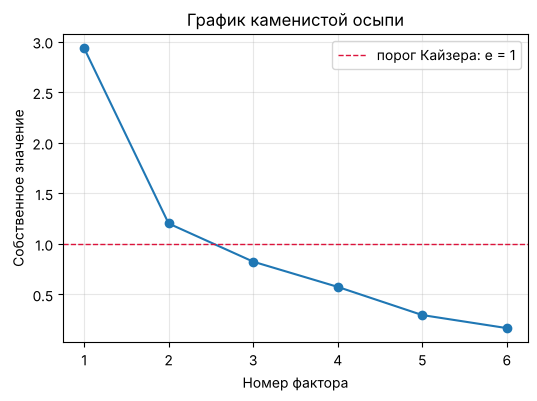

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, p_red + 1), eigenvalues, "o-")
ax.axhline(1, color="crimson", linestyle="--", linewidth=1, label="порог Кайзера: e = 1")
ax.set_xlabel("Номер фактора")
ax.set_ylabel("Собственное значение")
ax.set_title("График каменистой осыпи")
ax.set_xticks(np.arange(1, p_red + 1))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Выбор числа факторов.**
- Критерий Кайзера: $e > 1$ у двух факторов (2.936 и 1.202), третье значение 0.824.
- График осыпи: после второго фактора спад становится пологим (0.824, 0.575, 0.296, 0.167), перелом на втором факторе.
- Накопленная доля: два фактора объясняют 69.0 %, это попадает в ориентир 60–70 %.

Все три ориентира сходятся, выбрано $k = 2$.

**Документация:**
[`FactorAnalyzer.get_eigenvalues`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.FactorAnalyzer.get_eigenvalues),
[`matplotlib.pyplot.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html)

## Задание 3. Извлечение факторов, общности и остаточные корреляции

1.  Извлеките факторы методом максимального правдоподобия
    (`FactorAnalyzer(n_factors=k, method="ml", rotation=None)`) для
    числа факторов, выбранного в задании 2.
2.  Выведите матрицу нагрузок и общности переменных, вычислите среднюю
    общность.
3.  Вычислите остаточные корреляции $R - \Lambda\Lambda^\top$ с нулевой
    диагональю: максимальный остаток по модулю, среднеквадратичный
    остаток и число остатков больше 0,05.
4.  Оцените качество модели: какие переменные объясняются хорошо, какие
    плохо (ориентир общности 0,3), насколько малы остаточные корреляции.
    Какие выводы это подсказывает для интерпретации?

Результат задания: матрица нагрузок, общности и их среднее, три
показателя остатков, вывод о качестве модели.

Подготовительный код (выполняется без изменений; значение `k` замените
на выбранное в задании 2, если оно отличается):

In [16]:
fa_full = FactorAnalyzer(n_factors=p_red, rotation=None)
fa_full.fit(X_red)
k = int((fa_full.get_eigenvalues()[0] > 1).sum())
print("k по критерию Кайзера:", k)

k по критерию Кайзера: 2


In [17]:
fa_ml = FactorAnalyzer(n_factors=k, method="ml", rotation=None)
fa_ml.fit(X_red)
L = fa_ml.loadings_
communalities = fa_ml.get_communalities()

factor_cols = ["Ф" + str(i + 1) for i in range(k)]
loadings_table = pd.DataFrame(L.round(3), index=features, columns=factor_cols)
loadings_table["Общность"] = communalities.round(3)
print(loadings_table.to_string())
print("средняя общность: %.3f" % communalities.mean())
print("общность ниже 0.3:", [features[i] for i in range(p_red) if communalities[i] < 0.3])

                     Ф1     Ф2  Общность
fixed acidity     0.997  0.008     0.995
volatile acidity -0.262  0.728     0.599
citric acid       0.678 -0.515     0.725
density           0.668  0.224     0.496
pH               -0.685  0.128     0.486
sulphates         0.187 -0.307     0.129


средняя общность: 0.572
общность ниже 0.3: ['sulphates']


In [18]:
R = X_red.corr().to_numpy()
residuals = R - L @ L.T
np.fill_diagonal(residuals, 0.0)

res_values = residuals[np.triu_indices(p_red, 1)]  # каждая пара переменных один раз
print("максимальный |остаток|: %.4f" % np.abs(res_values).max())
print("среднеквадратичный остаток: %.4f" % np.sqrt(np.mean(res_values ** 2)))
print("остатков больше 0.05 по модулю:", int((np.abs(res_values) > 0.05).sum()), "из", len(res_values))

максимальный |остаток|: 0.0922
среднеквадратичный остаток: 0.0377
остатков больше 0.05 по модулю: 2 из 15


**Качество модели (ml, $k = 2$, без вращения).** Средняя общность 0.572. Хорошо объясняются `fixed acidity` (0.995), `citric acid` (0.725) и `volatile acidity` (0.599), средне `density` (0.496) и `pH` (0.486). У `sulphates` общность 0.129 ниже порога 0.3: сульфаты факторами почти не объясняются. Общность `fixed acidity` близка к 1, то есть фактор фактически совпадает с этой переменной.

Остатки небольшие: максимальный 0.0922, среднеквадратичный 0.0377, больше 0.05 только 2 остатка из 15 (пары `density`–`sulphates` и `density`–`pH`). Модель в целом хорошо воспроизводит корреляции. При интерпретации на сульфаты опираться нельзя, а связи плотности описаны не полностью.

## Задание 4. Вращение варимакс и интерпретация факторов

1.  Поверните матрицу нагрузок варимаксом: обучите модель с
    `rotation="varimax"` при том же методе и числе факторов. Выведите
    таблицу нагрузок после вращения.
2.  Проверьте инвариантность: вычислите суммы квадратов нагрузок по
    факторам до и после вращения и сверьте, что их сумма не изменилась,
    а общности переменных остались прежними.
3.  Реализуйте подсчёт простой структуры: число значимых нагрузок (по
    модулю больше 0,4) и число кросс-нагрузок, то есть переменных с
    двумя и более значимыми нагрузками. Найдите переменные с
    кросс-нагрузками и объясните их содержательно.
4.  Дайте содержательные имена факторам, опираясь на весь столбец
    нагрузок каждого фактора, и запишите интерпретацию: какие свойства
    вина описывает каждый фактор и почему знаки нагрузок устроены именно
    так.

Результат задания: таблица нагрузок после вращения, значения SS до и
после, число значимых нагрузок и кросс-нагрузок, названия факторов с
обоснованием.

Подготовительный код (выполняется без изменений):

In [19]:
fa_unrotated = FactorAnalyzer(n_factors=k, method="ml", rotation=None)
fa_unrotated.fit(X_red)
L_unrotated = fa_unrotated.loadings_

In [20]:
fa_var = FactorAnalyzer(n_factors=k, method="ml", rotation="varimax")
fa_var.fit(X_red)
L_varimax = fa_var.loadings_
print(pd.DataFrame(L_varimax.round(3), index=features, columns=factor_cols).to_string())

ss_before = fa_unrotated.get_factor_variance()[0]
ss_after = fa_var.get_factor_variance()[0]
print("SS до вращения:", ss_before.round(3), "сумма:", round(ss_before.sum(), 3))
print("SS после вращения:", ss_after.round(3), "сумма:", round(ss_after.sum(), 3))
print("общности до вращения:   ", fa_unrotated.get_communalities().round(3))
print("общности после вращения:", fa_var.get_communalities().round(3))

                     Ф1     Ф2
fixed acidity     0.954  0.293
volatile acidity -0.031 -0.773
citric acid       0.491  0.696
density           0.704 -0.012
pH               -0.615 -0.329
sulphates         0.086  0.349
SS до вращения: [2.474 0.956] сумма: 3.43
SS после вращения: [2.033 1.397] сумма: 3.43
общности до вращения:    [0.995 0.599 0.725 0.496 0.486 0.129]
общности после вращения: [0.995 0.599 0.725 0.496 0.486 0.129]


In [21]:
significant = np.abs(L_varimax) > 0.4
n_per_variable = significant.sum(axis=1)
cross_vars = [features[i] for i in range(p_red) if n_per_variable[i] >= 2]
print("значимых нагрузок (|нагрузка| > 0.4):", int(significant.sum()))
print("кросс-нагрузок:", len(cross_vars), cross_vars)

factor_names = ["Общая кислотность", "Свежесть (лимонная против летучей)"]
print(pd.DataFrame(L_varimax.round(3), index=features, columns=factor_names).to_string())

значимых нагрузок (|нагрузка| > 0.4): 6
кросс-нагрузок: 1 ['citric acid']
                  Общая кислотность  Свежесть (лимонная против летучей)
fixed acidity                 0.954                               0.293
volatile acidity             -0.031                              -0.773
citric acid                   0.491                               0.696
density                       0.704                              -0.012
pH                           -0.615                              -0.329
sulphates                     0.086                               0.349


**Интерпретация факторов (ml, $k = 2$, varimax).**

Суммы квадратов нагрузок перераспределились: 2.474 и 0.956 до вращения, 2.033 и 1.397 после, сумма в обоих случаях 3.430. Общности не изменились. Значимых нагрузок 6, кросс-нагрузка одна: `citric acid` (0.491 и 0.696).

- **Ф1 — «общая кислотность».** Высокие положительные нагрузки у `fixed acidity` (0.954), `density` (0.704) и `citric acid` (0.491), отрицательная у `pH` (−0.615). Чем больше в вине нелетучих кислот, тем ниже pH, поэтому знаки противоположны. Растворённые кислоты повышают плотность, поэтому плотность идёт с тем же знаком, что и кислотность.
- **Ф2 — «свежесть: лимонная кислота против летучей».** Фактор биполярный: `citric acid` (0.696) и `sulphates` (0.349) с одной стороны, `volatile acidity` (−0.773) с другой. Летучая кислотность (уксусная кислота) растёт при порче вина, а лимонная кислота и сульфаты связаны с более свежими и защищёнными винами. Высокое значение фактора означает больше лимонной кислоты и меньше летучей.

Знак столбца произволен: при умножении Ф2 на −1 он читался бы как «летучая кислотность». Порядок факторов тоже задаёт программа.

Кросс-нагрузка `citric acid` содержательно понятна: лимонная кислота входит в общую титруемую кислотность (Ф1) и одновременно противопоставлена летучей кислотности (Ф2), так как их корреляция −0.55.

**Документация:**
[`FactorAnalyzer`](https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.FactorAnalyzer)

## Задание 5. Сквозной анализ и итоговый отчёт

Соберите полный анализ отобранного набора и сравните альтернативные
решения. Каждое решение оценивается по одинаковым метрикам: суммарная
доля объяснённой дисперсии, число значимых нагрузок, число
кросс-нагрузок, средняя общность, максимальный остаток.

1.  Сравните вращения: варимакс и квартимакс (`rotation="quartimax"`)
    при выбранном числе факторов. Какое вращение даёт более простую
    структуру? Обратите внимание, что суммарные метрики при
    ортогональном вращении совпадают, поэтому сравнивать нужно
    распределение дисперсии по факторам и интерпретируемость.
2.  Сравните число факторов: выбранное в задании 2 и на один больше. Что
    добавляет лишний фактор с точки зрения содержания и интерпретации?
    Учтите, что после вращения суммарная объяснённая дисперсия не
    растёт, а рост означал бы ошибку в расчётах.
3.  Подготовьте итоговый отчёт в markdown-ячейке: пригодность данных
    (Бартлетт, KMO, отбор переменных), метод извлечения, число факторов
    и его обоснование, тип вращения, таблица нагрузок и общностей,
    содержательная интерпретация факторов, ограничения решения (какие
    переменные объясняются слабо, где остались кросс-нагрузки) и вывод о
    скрытых измерениях, которые стоят за химическими показателями
    красного вина.

Результат задания: сравнительная таблица методов и чисел факторов,
таблицы нагрузок, итоговый отчёт в markdown-ячейке.

Подготовительный код (выполняется без изменений):

In [22]:
fa_varimax = FactorAnalyzer(n_factors=k, method="ml", rotation="varimax").fit(X_red)
fa_quartimax = FactorAnalyzer(n_factors=k, method="ml", rotation="quartimax").fit(X_red)
fa_three = FactorAnalyzer(n_factors=k + 1, method="ml", rotation="varimax").fit(X_red)
R_red = X_red.corr().to_numpy()

In [23]:
models = {
    "k=2, без вращения": fa_unrotated,
    "k=2, varimax": fa_varimax,
    "k=2, quartimax": fa_quartimax,
    "k=3, без вращения": FactorAnalyzer(n_factors=k + 1, method="ml", rotation=None).fit(X_red),
    "k=3, varimax": fa_three,
}

rows = []
for name, model in models.items():
    L_model = model.loadings_
    E = R_red - L_model @ L_model.T
    np.fill_diagonal(E, 0.0)
    significant = np.abs(L_model) > 0.4
    rows.append({
        "Решение (ml)": name,
        "SS по факторам": model.get_factor_variance()[0].round(3),
        "Доля дисперсии, %": round(model.get_factor_variance()[2][-1] * 100, 1),
        "Значимых": int(significant.sum()),
        "Кросс-нагрузок": int((significant.sum(axis=1) >= 2).sum()),
        "Средняя общность": round(model.get_communalities().mean(), 3),
        "Макс. остаток": round(np.abs(E).max(), 4),
    })
print(pd.DataFrame(rows).to_string(index=False))

     Решение (ml)        SS по факторам  Доля дисперсии, %  Значимых  Кросс-нагрузок  Средняя общность  Макс. остаток
k=2, без вращения        [2.474, 0.956]               57.2         6               1             0.572         0.0922
     k=2, varimax        [2.033, 1.397]               57.2         6               1             0.572         0.0922
   k=2, quartimax        [2.405, 1.025]               57.2         6               1             0.572         0.0922
k=3, без вращения [1.799, 1.621, 0.524]               65.7         7               2             0.657         0.0527
     k=3, varimax [1.594, 1.207, 1.143]               65.7         7               2             0.657         0.0527


In [24]:
for name in ["k=2, varimax", "k=2, quartimax", "k=3, varimax"]:
    model = models[name]
    cols = ["Ф" + str(i + 1) for i in range(model.n_factors)]
    table = pd.DataFrame(model.loadings_.round(3), index=features, columns=cols)
    table["Общность"] = model.get_communalities().round(3)
    print(name)
    print(table.to_string())
    print()

k=2, varimax
                     Ф1     Ф2  Общность
fixed acidity     0.954  0.293     0.995
volatile acidity -0.031 -0.773     0.599
citric acid       0.491  0.696     0.725
density           0.704 -0.012     0.496
pH               -0.615 -0.329     0.486
sulphates         0.086  0.349     0.129

k=2, quartimax
                     Ф1     Ф2  Общность
fixed acidity     0.996 -0.051     0.995
volatile acidity -0.218  0.742     0.599
citric acid       0.646 -0.555     0.725
density           0.680  0.183     0.496
pH               -0.676  0.169     0.486
sulphates         0.168 -0.317     0.129

k=3, varimax
                     Ф1     Ф2     Ф3  Общность
fixed acidity     0.841  0.227  0.418     0.933
volatile acidity -0.173 -0.698  0.122     0.532
citric acid       0.528  0.690  0.172     0.785
density           0.308  0.058  0.947     0.995
pH               -0.692 -0.220 -0.122     0.542
sulphates         0.069  0.375  0.111     0.158



**Сравнение решений.**

Варимакс и квартимакс при $k = 2$ совпадают по всем суммарным метрикам: 57.2 % дисперсии, 6 значимых нагрузок, 1 кросс-нагрузка, средняя общность 0.572, максимальный остаток 0.0922. Различается распределение дисперсии: квартимакс оставляет почти общий первый фактор (SS 2.405 и 1.025), на который заметно нагружены и `volatile acidity` (−0.218), и `citric acid` (0.646 и −0.555). Варимакс распределяет дисперсию ровнее (2.033 и 1.397), вторичные нагрузки у `fixed acidity`, `volatile acidity` и `density` меньше, факторы читаются отдельно. Структура варимакса проще, он выбран для итогового решения.

При $k = 3$ доля дисперсии выросла до 65.7 % за счёт дополнительного фактора, а не вращения: без вращения и после варимакса она одинакова (65.7 %), как и должно быть. Третий фактор почти целиком состоит из `density` (0.947, общность 0.995), то есть это фактор одной переменной. Кросс-нагрузок стало две (`fixed acidity` и `citric acid`), остатки уменьшились (0.0527), но при шести переменных модель с тремя факторами имеет 0 степеней свободы и уже насыщена. Новых содержательных измерений третий фактор не добавляет, поэтому остаёмся на $k = 2$.

## Итоговый отчёт

**Данные и пригодность.** 1599 образцов красного вина, 11 химических показателей (`quality` не использовалась). Для полного набора KMO 0.4321 — неприемлемо. Итеративным отбором по индивидуальному KMO (порог 0.5) исключены `residual sugar`, `alcohol`, `chlorides`, `total sulfur dioxide`, `free sulfur dioxide`. Для оставшихся 6 переменных KMO 0.6796 (удовлетворительно), тест Бартлетта $\chi^2 = 3974.04$, $\mathrm{df} = 15$, $p < 0.001$. Данные пригодны для факторного анализа.

**Метод и число факторов.** Метод извлечения — максимальное правдоподобие (`method="ml"`). Число факторов $k = 2$: два собственных значения больше 1 (2.936 и 1.202), перелом на графике осыпи после второго фактора, накопленная доля 69.0 %.

**Вращение.** Ортогональное, варимакс.

**Нагрузки и общности (ml, $k = 2$, varimax):**

| Переменная | Ф1 «общая кислотность» | Ф2 «свежесть» | Общность |
|---|---|---|---|
| fixed acidity | **0.954** | 0.293 | 0.995 |
| volatile acidity | −0.031 | **−0.773** | 0.599 |
| citric acid | **0.491** | **0.696** | 0.725 |
| density | **0.704** | −0.012 | 0.496 |
| pH | **−0.615** | −0.329 | 0.486 |
| sulphates | 0.086 | 0.349 | 0.129 |
| SS нагрузок | 2.033 | 1.397 | сумма 3.430 |

Факторы объясняют 57.2 % дисперсии, средняя общность 0.572, максимальный остаток 0.0922, среднеквадратичный 0.0377, остатков больше 0.05 — 2 из 15.

**Интерпретация.** Ф1 — общая (титруемая) кислотность: нелетучие кислоты, связанная с ними плотность и обратно связанный pH. Ф2 — свежесть вина: противопоставление лимонной кислоты и сульфатов летучей (уксусной) кислотности.

**Ограничения.** `sulphates` объясняются слабо (общность 0.129 < 0.3). У `citric acid` осталась кросс-нагрузка. Общность `fixed acidity` близка к 1, первый фактор во многом совпадает с этой переменной. Связи `density` с `pH` и `sulphates` воспроизведены хуже остальных. Пять показателей исключены, поэтому сахар, спирт, соли и диоксид серы моделью не описываются.

**Вывод.** За отобранными химическими показателями красного вина стоят два скрытых измерения: уровень общей кислотности и свежесть вина (лимонная кислота против летучей). Эти факторы объясняют связи между показателями кислотности, pH и плотности, но не охватывают остальной химический состав вина.

## Критерии самопроверки

| Что проверить | Признак корректного выполнения |
|------------------------------------|------------------------------------|
| Отбор переменных | цикл остановлен по порогу 0,5; приведены исключённые переменные и траектория общего KMO |
| Пригодность набора | указаны статистика, степени свободы и p-значение теста Бартлетта, общий KMO, сделан вывод о применимости |
| Число факторов | таблица собственных значений с долями и накопленными долями; выбор обоснован не менее чем двумя ориентирами |
| Извлечение | указан метод `ml`, число факторов, приведены нагрузки и общности, отмечены переменные с общностью ниже 0,3 |
| Остатки | приведены максимальный модуль, среднеквадратичный остаток и число остатков больше 0,05 |
| Вращение | показано, что суммы квадратов перераспределились, а их сумма и общности не изменились |
| Простая структура | подсчитаны значимые нагрузки и кросс-нагрузки, кросс-нагрузки объяснены содержательно |
| Интерпретация | факторы названы по всему столбцу нагрузок, знаки нагрузок объяснены, учтена произвольность знаков и порядка |
| Итоговый отчёт | указаны метод, число факторов и тип вращения, таблица результатов, интерпретация и ограничения |
| Воспроизводимость | не объявлено собственных функций, используются готовые функции пакета; данные читаются из `data/` |

## Контрольные вопросы

1.  Что описывает модель факторного анализа и чем латентный фактор
    отличается от наблюдаемой переменной?
2.  Как связаны общность и характерность стандартизованной переменной и
    какую роль играет порог 0,3?
3.  Какую гипотезу проверяет тест сферичности Бартлетта и как читается
    его p-значение?
4.  Что показывает KMO и как интерпретируются его градации? Почему важно
    смотреть KMO по отдельным переменным?
5.  Почему сумма собственных значений корреляционной матрицы равна числу
    переменных, а не единице?
6.  Как работают критерий Кайзера и график каменистой осыпи и почему их
    результаты могут расходиться?
7.  Зачем нужно вращение нагрузок и что оно не меняет в решении?
8.  Чем ортогональное вращение отличается от косоугольного и когда
    уместно каждое?
9.  Что такое кросс-нагрузка и как поступить с переменной, которая её
    имеет?
10. Назовите типичные ошибки подготовки данных и интерпретации
    результатов факторного анализа.

## Документация

| Объект | Ссылка |
|------------------------------------|------------------------------------|
| `factor_analyzer.FactorAnalyzer` | https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.FactorAnalyzer |
| `factor_analyzer.calculate_kmo` | https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.calculate_kmo |
| `factor_analyzer.calculate_bartlett_sphericity` | https://factor-analyzer.readthedocs.io/en/latest/factor_analyzer.html#factor_analyzer.factor_analyzer.calculate_bartlett_sphericity |
| Руководство пользователя `factor_analyzer` | https://factor-analyzer.readthedocs.io/en/latest/index.html |
| `pandas.read_csv` | https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html |
| `pandas.DataFrame.corr` | https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html |
| `matplotlib.pyplot.plot` | https://matplotlib.org/stable/api/\_as_gen/matplotlib.pyplot.plot.html |

## Ответы на контрольные вопросы

1. Модель описывает каждую переменную как линейную комбинацию общих факторов и собственной составляющей, поэтому корреляции объясняются общими факторами. Наблюдаемая переменная измеряется напрямую, а латентный фактор вычисляется по корреляционной матрице.
2. Для стандартизованной переменной $h_i^2 + \psi_i = 1$: общность — доля дисперсии, объяснённая факторами, характерность — остальная часть. При $h_i^2 < 0.3$ переменная факторами почти не объясняется (в работе — `sulphates`, 0.129).
3. Тест проверяет $H_0$: корреляционная матрица единичная, то есть переменные не связаны. При $p < 0.05$ $H_0$ отвергается и факторный анализ применим, при $p > 0.05$ — не оправдан.
4. KMO сравнивает обычные корреляции с частными; чем ближе к 1, тем лучше: > 0.9 отлично, 0.8–0.9 хорошо, 0.7–0.8 посредственно, 0.6–0.7 удовлетворительно, 0.5–0.6 плохо, < 0.5 неприемлемо. KMO по переменным показывает, какие из них не вписываются в общую структуру и мешают анализу.
5. Сумма собственных значений равна следу корреляционной матрицы, а на её диагонали стоят единицы, поэтому сумма равна числу переменных $p$.
6. Критерий Кайзера оставляет факторы с $e > 1$, график осыпи — факторы до перелома. Критерий Кайзера смотрит на фиксированный порог, а осыпь — на форму спада, поэтому они могут давать разное число факторов.
7. Вращение нужно для простой структуры, чтобы факторы легче читались. Оно не меняет общности, суммарную объяснённую дисперсию и остатки.
8. Ортогональное вращение (варимакс, квартимакс) оставляет факторы некоррелированными, косоугольное (промакс, облимин) допускает их корреляцию. Ортогональное уместно, когда факторы можно считать независимыми, косоугольное — когда они содержательно связаны.
9. Кросс-нагрузка — значимая нагрузка переменной сразу на два и более фактора. Её объясняют содержательно; если она мешает интерпретации, пробуют другое вращение или число факторов, либо исключают переменную.
10. Ошибки подготовки: не проверить Бартлетта и KMO, не пересчитать KMO после исключения переменной, выбросы, малая выборка. Ошибки интерпретации: механически брать все $e > 1$, называть фактор по одной переменной, игнорировать кросс-нагрузки, считать фактор причиной, не указывать метод, число факторов и вращение.